<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>واجب مستقل · ثلاث فئات</h2><p>توسعة المشروع إلى <bdi dir="ltr">NORMAL / BACTERIAL / VIRAL</bdi>. سنقسم فئة PNEUMONIA وفق <code dir="ltr">bacteria</code> و<code dir="ltr">virus</code> الموجودة في أسماء الملفات الأصلية. لا توجد فئة ثالثة باسم PNEUMONIA3.</p><p>ابدأ Kernel جديدة. أكمل HW01–HW03، ثم درّب النموذج وفسّر النتائج في H13. مدة تقديرية 60–90 دقيقة للعمل، إضافة إلى وقت التدريب حسب جهازك. نتائج المهمة تعليمية وتعتمد على Labels المصدر.</p></div><div style="clear:both"></div></div>

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H00 · تجهيز نسخة البيانات</h2><p>شغّل هذه الخلية كما هي. تنسخ الصور إلى مجلد مستقل بثلاث فئات مع الحفاظ على Train وValidation وTest. توقف الأداة إذا وجدت اسمًا غير معروف بدل تخمين Label. لا تعدّل المجلد الأصلي.</p><table><tr><th>Split</th><th>BACTERIAL</th><th>NORMAL</th><th>VIRAL</th></tr><tr><td>Train</td><td>1771</td><td>1071</td><td>992</td></tr><tr><td>Validation</td><td>404</td><td>270</td><td>251</td></tr><tr><td>Test</td><td>242</td><td>234</td><td>148</td></tr></table><p>المصدر: <a href="https://data.mendeley.com/datasets/rscbjbr9sj/2">Kermany et al., Mendeley Data</a>، ترخيص CC BY 4.0. التقسيم المجهّز للحصة موثق في <code dir="ltr">data/SOURCE_AND_LICENSE.txt</code>.</p></div><div style="clear:both"></div></div>

In [1]:
from prepare_three_classes import prepare_dataset
prepared_path = prepare_dataset()

Three-class dataset ready. Original images and splits are unchanged.
Split     BACTERIAL  NORMAL  VIRAL  Total
train          1771    1071    992   3834
val             404     270    251    925
test            242     234    148    624


<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H01 · إعدادات الواجب</h2><p><b>HW01:</b> استخدم مسار المجلد الذي جهزناه في H00. أول تشغيل يحتاج <code dir="ltr">TRAIN_NOW=True</code>. بعد إكمال H09 يمكنك لاحقًا اختيار False لتحميل نموذجك الثلاثي المحفوظ. نستخدم 3 Epochs كبداية، ونختار الإعدادات بواسطة Validation.</p></div><div style="clear:both"></div></div>

In [2]:
from pathlib import Path
import copy
import random
import time
import sys
from tqdm import tqdm
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from helpers import show_batch, plot_history, plot_confusion, show_prediction, show_gradcam

# نثبت البداية قدر الإمكان لتسهيل مقارنة التجارب.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

# نضع الإعدادات التي سنغيّرها أثناء التجربة في مكان واحد.
IMAGE_SIZE, BATCH_SIZE, EPOCHS = 224, 32, 3
LEARNING_RATE = 0.001
TRAIN_NOW = True
# النموذج والبيانات يجب أن يكونا على Device نفسها.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# HW01: Point to the newly prepared three-class folder.
DATA_DIR = Path("data/chest_xray_3class")
assert DATA_DIR.is_dir(), "Run H00 to prepare the three-class folders."
# نستخدم Initial Weights المرفقة لتجنب التحميل أثناء الدرس.
torch.hub.set_dir("artifacts/torch")
print("Device:", device)
print("PyTorch:", torch.__version__)


Device: cuda
PyTorch: 2.6.0+cu124


<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H02 · قراءة الصور وLabels</h2><p>نقرأ المجلد الجديد بفئاته الثلاث. ترتيب ImageFolder أبجدي، لذلك نطبع <code dir="ltr">class_to_idx</code> بدل افتراض أن NORMAL تحمل الرقم 0. الإجمالي نفسه: Train 3834، Validation 925، Test 624.</p></div><div style="clear:both"></div></div>

In [3]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
# نطبق العمليات بالترتيب نفسه على كل صورة.
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# أسماء المجلدات تحدد Classes، وTransform تجهز الصورة عند قراءتها.
train_data = datasets.ImageFolder(DATA_DIR / "train", transform=transform)
val_data = datasets.ImageFolder(DATA_DIR / "val", transform=transform)
test_data = datasets.ImageFolder(DATA_DIR / "test", transform=transform)
class_names = train_data.classes
# نتحقق أن معنى الأرقام متطابق في Train وValidation وTest.
assert class_names == ["BACTERIAL", "NORMAL", "VIRAL"]
assert train_data.class_to_idx == val_data.class_to_idx == test_data.class_to_idx

print("Class mapping:", train_data.class_to_idx)
for name, dataset in [("Train", train_data), ("Validation", val_data), ("Test", test_data)]:
    counts = np.bincount(dataset.targets, minlength=len(class_names))
    print(name, len(dataset), dict(zip(class_names, counts.tolist())))

Class mapping: {'BACTERIAL': 0, 'NORMAL': 1, 'VIRAL': 2}
Train 3834 {'BACTERIAL': 1771, 'NORMAL': 1071, 'VIRAL': 992}
Validation 925 {'BACTERIAL': 404, 'NORMAL': 270, 'VIRAL': 251}
Test 624 {'BACTERIAL': 242, 'NORMAL': 234, 'VIRAL': 148}


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">H03</bdi> · تجهيز Batches</h2>
<p>يجمع DataLoader الصور في Batches؛ الشكل <code dir="ltr">[N, 3, 224, 224]</code> يعني عدد الصور ثم Channels ثم الارتفاع والعرض. نعرض Batch واحدة للتحقق من الصور وLabels.</p>
</div>
<div style="clear:both;"></div>
</div>

Images: (32, 3, 224, 224) torch.float32
Labels: (32,) torch.int64


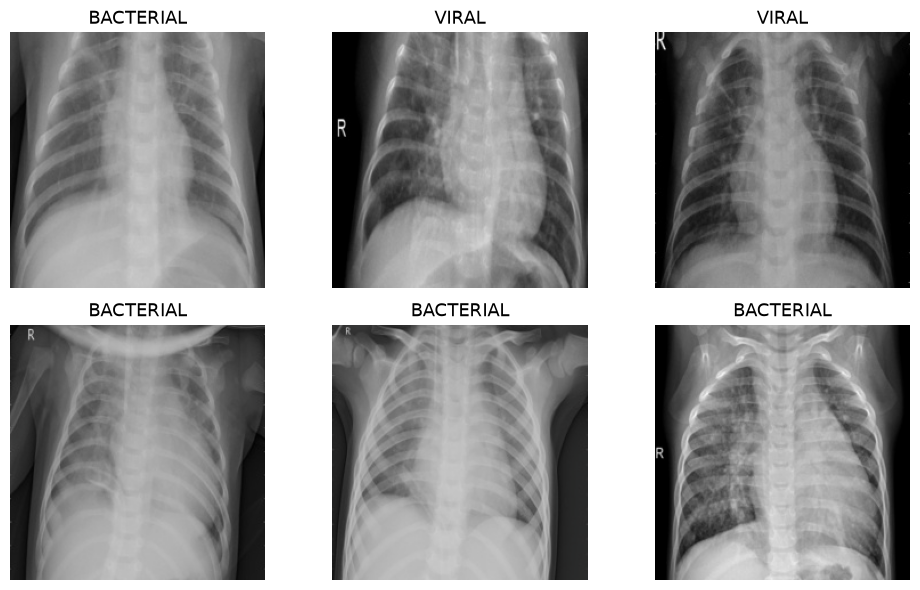

In [4]:
# نجمع الصور في Batches ونخلط Train فقط.
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# نأخذ Batch واحدة لنرى ما يدخل إلى النموذج.
images, labels = next(iter(train_loader))
print("Images:", tuple(images.shape), images.dtype)
print("Labels:", tuple(labels.shape), labels.dtype)
show_batch(images, labels, class_names, MEAN, STD)

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H04 · Classifier لثلاث فئات</h2><p><b>HW02:</b> أنشئ Linear بعدد Outputs يساوي <code dir="ltr">len(class_names)</code>. تبقى CrossEntropyLoss مناسبة: تستقبل Logits بأبعاد <bdi dir="ltr">[N, 3]</bdi> وLabels صحيحة بأبعاد <bdi dir="ltr">[N]</bdi>.</p></div><div style="clear:both"></div></div>

In [5]:
# نبدأ من Weights تعلمت Features عامة على ImageNet.
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)

# نثبت Backbone وندرّب Classifier الجديدة فقط.
for parameter in model.features.parameters():
    parameter.requires_grad = False
# آخر Layer تخرج درجة لكل Class في مشروعنا.
# HW02: Replace the next line with a head assignment for all classes.
model.classifier[-1] = nn.Linear(model.last_channel, len(class_names))
model = model.to(device)
# هذه Loss تستقبل Logits مباشرة، لذلك لا نضيف Softmax هنا.
loss_fn = nn.CrossEntropyLoss()
# نعطي Optimizer Parameters الخاصة بـClassifier فقط.
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Classifier:", model.classifier)
print("Trainable parameters:", trainable)


Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)
Trainable parameters: 3843


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">H05</bdi> · تعريف Training Loop</h2>
<p>الدالة <code dir="ltr">run_epoch</code> تعالج مرورًا واحدًا على البيانات. <code dir="ltr">training=True</code> يحسب Gradients ويحدّث Weights؛ <code dir="ltr">False</code> يقيس الأداء فقط، وتعريف الدالة هنا لا يشغّل التدريب.</p>
</div>
<div style="clear:both;"></div>
</div>

In [6]:
def run_epoch(loader, training):
    # نفعّل Training behavior أو Evaluation behavior حسب المرحلة.
    model.train(training)
    # نبقي Backbone ثابتة، بما فيها إحصاءات BatchNorm.
    model.features.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    phase = "Training" if training else "Validation"

    # يظهر Progress Bar قبل قراءة أول Batch، ويتحدث بعد اكتمالها.
    with tqdm(total=len(loader), desc=phase, unit="batch",
              file=sys.stdout, dynamic_ncols=True, mininterval=0.5) as progress:
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                # نبدأ Batch جديدة بدون Gradients متراكمة من السابقة.
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                # Forward Pass ثم قياس الخطأ مقارنةً بـLabels الصحيحة.
                logits = model(x)
                loss = loss_fn(logits, y)
                if training:
                    # نحسب Gradients أولًا، ثم نحدّث Weights.
                    loss.backward()
                    optimizer.step()
            # نزن Loss بعدد الصور؛ آخر Batch قد تكون أصغر.
            total_loss += loss.item() * len(y)
            # == تقارن Prediction بـLabel؛ نجمع عدد الإجابات الصحيحة.
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total += len(y)

            # المتوسط محسوب على الصور التي اكتملت حتى الآن.
            progress.set_postfix(Loss=f"{total_loss / total:.4f}",
                                 Accuracy=f"{total_correct / total:.1%}", refresh=False)
            progress.update(1)
    return total_loss / total, total_correct / total

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H06 · تدريب النموذج الثلاثي</h2><p>أول تشغيل يحتاج <code dir="ltr">TRAIN_NOW=True</code>. أوزان ImageNet جاهزة، أما Classifier ذات الثلاثة Outputs فتتدرب هنا. النموذج المرجعي الثنائي لا يصلح لتحميله في هذا المسار. نختار أقل Validation Loss. اضبط Epochs وLearning Rate باستخدام Validation قبل التقييم النهائي.</p></div><div style="clear:both"></div></div>

In [7]:
run_source = None
print(f"H06 started | TRAIN_NOW={TRAIN_NOW} | Device={device}", flush=True)
if TRAIN_NOW:
    if not isinstance(EPOCHS, int) or EPOCHS < 1:
        raise ValueError("EPOCHS must be a positive integer.")
    print(f"Starting training: {EPOCHS} epoch(s) | "
          f"Train: {len(train_loader)} batches | Validation: {len(val_loader)} batches",
          flush=True)
    history = []
    best_loss, best_epoch, best_state = float("inf"), 0, None
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        print(f"\nEpoch {epoch}/{EPOCHS}", flush=True)
        train_loss, train_acc = run_epoch(train_loader, training=True)
        val_loss, val_acc = run_epoch(val_loader, training=False)
        history.append([train_loss, val_loss, train_acc, val_acc])
        print(f"Epoch {epoch}: Train loss={train_loss:.3f}, acc={train_acc:.1%} | "
              f"Val loss={val_loss:.3f}, acc={val_acc:.1%}", flush=True)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            # نسخة مستقلة من أفضل Weights حتى الآن.
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    training_seconds = time.perf_counter() - started
    run_source = "trained_here"
    print(f"Training complete. Selected epoch: {best_epoch}; "
          f"training time: {training_seconds:.1f} seconds", flush=True)
else:
    checkpoint_path = Path("artifacts/pneumonia_3class.pt")
    if not checkpoint_path.is_file():
        raise FileNotFoundError("No three-class checkpoint yet. Set TRAIN_NOW=True and rerun H01-H06.")
    print("Loading your three-class checkpoint...", flush=True)
    reference = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    assert reference["class_names"] == class_names, "Checkpoint classes differ."
    model.load_state_dict(reference["state_dict"])
    history, best_epoch = reference["history"], reference["best_epoch"]
    training_seconds = 0.0
    run_source = "loaded_3class"
    print("Loaded your three-class checkpoint. No training was run in this session.", flush=True)

H06 started | TRAIN_NOW=True | Device=cuda


Starting training: 3 epoch(s) | Train: 120 batches | Validation: 29 batches



Epoch 1/3


Training:   0%|          | 0/120 [00:00<?, ?batch/s]

Training:   1%|          | 1/120 [00:01<03:24,  1.72s/batch, Accuracy=34.4%, Loss=1.1351]

Training:   2%|▏         | 2/120 [00:02<01:59,  1.02s/batch, Accuracy=34.4%, Loss=1.0965]

... (456 outputs left out)

Validation: 100%|██████████| 29/29 [00:19<00:00,  1.56batch/s, Accuracy=77.1%, Loss=0.5606]

Validation: 100%|██████████| 29/29 [00:19<00:00,  1.47batch/s, Accuracy=77.1%, Loss=0.5606]


Epoch 3: Train loss=0.495, acc=79.8% | Val loss=0.561, acc=77.1%


Training complete. Selected epoch: 3; training time: 315.3 seconds


<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H07 · Learning Curves</h2><p>اعرض نتائج تدريبك الفعلية. لا تقارن Accuracy هذا الواجب مباشرة بنتيجة الفئتين لأن المهمة تغيرت. زيادة Epochs قد تساعد وقد تزيد Overfitting، والحكم يستخدم Validation.</p></div><div style="clear:both"></div></div>

Run source: trained_here


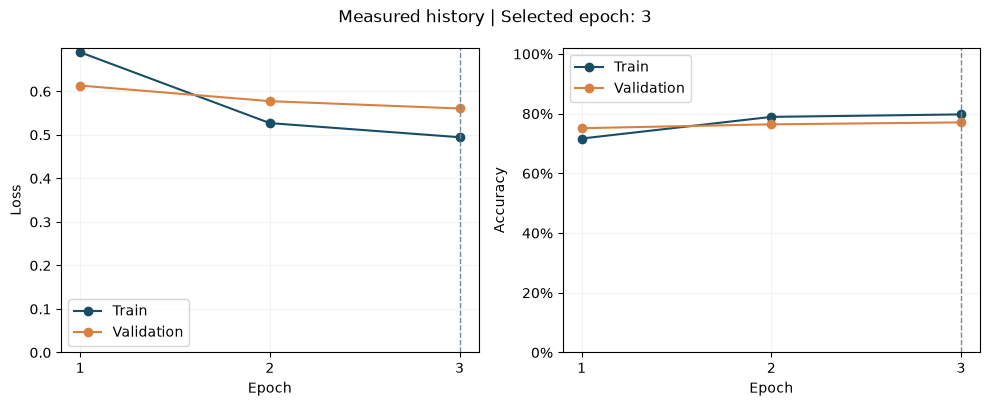

In [8]:
# نرسم القياسات المسجلة فعلًا، مع تحديد مصدرها.
print("Run source:", run_source)
plot_history(history, best_epoch, output="homework_outputs/learning_curves.png")

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H08 · التقييم النهائي لكل Class</h2><p><b>HW03:</b> نريد Recall مستقلة لكل Class؛ اختر قيمة <code dir="ltr">average</code> المناسبة بدل استخدام <code dir="ltr">pos_label=1</code> للفئة الواحدة. <code dir="ltr">None</code> تعني الاحتفاظ بنتيجة كل Class، بينما <code dir="ltr">macro</code> تعطي المتوسط مباشرة.</p><p>بعد تثبيت الإعدادات باستخدام Validation، نقيّم كل صور Test مرة واحدة. ينبغي أن تكون Confusion Matrix بأبعاد <bdi dir="ltr">3 × 3</bdi>. Macro recall هو متوسط Recall للفئات الثلاث بأوزان متساوية.</p></div><div style="clear:both"></div></div>

Test accuracy: 78.5%; Macro recall: 77.8%
BACTERIAL recall: 94.6%
NORMAL recall: 64.5%
VIRAL recall: 74.3%
Rows = true labels; columns = predictions


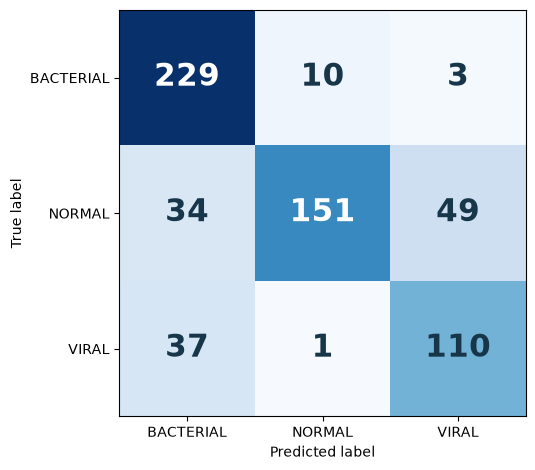

In [9]:
model.eval()
true_labels, predicted_labels = [], []
with torch.inference_mode():
    for x, y in test_loader:
        logits = model(x.to(device))
        true_labels.extend(y.tolist())
        predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())

class_ids = list(range(len(class_names)))
test_accuracy = accuracy_score(true_labels, predicted_labels)
# HW03: Keep a separate recall value for each class.
recall_average = None
per_class_recall = recall_score(true_labels, predicted_labels,
                                labels=class_ids, average=recall_average, zero_division=0)
assert np.shape(per_class_recall) == (len(class_names),), "Return one recall per class."
macro_recall = float(np.mean(per_class_recall))
cm = confusion_matrix(true_labels, predicted_labels, labels=class_ids)
print(f"Test accuracy: {test_accuracy:.1%}; Macro recall: {macro_recall:.1%}")
for name, recall in zip(class_names, per_class_recall):
    print(f"{name} recall: {recall:.1%}")
print("Rows = true labels; columns = predictions")
plot_confusion(cm, class_names, output="homework_outputs/confusion_matrix.png")


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">H09</bdi> · حفظ النموذج وإعادة تحميله</h2>
<p>نحفظ Weights وأسماء Classes وإعدادات المعالجة في Checkpoint، ثم نعيد تحميلها إلى نموذج جديد. حفظ هذه المعلومات يتيح استخدام المعالجة نفسها وفهم ترتيب المخرجات.</p>
</div>
<div style="clear:both;"></div>
</div>

In [10]:
# نحفظ مصدر النموذج الذي اكتمل في H06، مع Weights وإعدادات المعالجة.
assert run_source in {"trained_here", "loaded_3class"}, "Complete H06 first."
checkpoint = {
    "state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "mean": MEAN,
    "std": STD,
    "architecture": "mobilenet_v2",
    "best_epoch": best_epoch,
    "history": history,
    "run_source": run_source,
}
Path("artifacts").mkdir(exist_ok=True)
torch.save(checkpoint, "artifacts/pneumonia_3class.pt")

# نفتح الملف في نموذج جديد للتأكد أن الحفظ قابل للاستخدام.
saved = torch.load("artifacts/pneumonia_3class.pt", map_location="cpu", weights_only=True)
deployed_model = models.mobilenet_v2(weights=None)
deployed_model.classifier[-1] = nn.Linear(deployed_model.last_channel, len(saved["class_names"]))
deployed_model.load_state_dict(saved["state_dict"])
deployed_model = deployed_model.to(device).eval()
print("Saved and reloaded: artifacts/pneumonia_3class.pt")

Saved and reloaded: artifacts/pneumonia_3class.pt


<div style="display:flow-root; width:100%;">
<div dir="rtl" lang="ar" style="float:right; width:100%; box-sizing:border-box; text-align:right; font-family:Cairo,Tahoma,Arial,sans-serif; line-height:1.9;">
<h2><bdi dir="ltr">H10</bdi> · تعريف Prediction لصورة واحدة</h2>
<p>الدالة <code dir="ltr">predict</code> تعالج صورة واحدة وتعيد Label وScores لكل فئة. تضيف <code dir="ltr">unsqueeze(0)</code> محور Batch، وتحوّل Softmax Logits إلى Scores للعرض؛ Scores ليست احتمالات تشخيص طبي معايرة.</p>
</div>
<div style="clear:both;"></div>
</div>

In [11]:
# نعيد المعالجة نفسها التي حفظناها مع Checkpoint.
prediction_transform = transforms.Compose([
    transforms.Resize((saved["image_size"], saved["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(saved["mean"], saved["std"]),
])

def predict(image_path):
    image = Image.open(image_path).convert("RGB")
    # نضيف بُعد Batch: صورة واحدة تصبح [1, 3, 224, 224].
    x = prediction_transform(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        # Softmax للعرض بعد Prediction، وليست قبل Training Loss.
        scores = deployed_model(x).softmax(dim=1)[0].cpu()
    index = int(scores.argmax().item())
    # Dictionary: اسم Class، ثم Score لكل Class.
    return {"label": saved["class_names"][index],
            "scores": {name: float(scores[i]) for i, name in enumerate(saved["class_names"])}}

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H11 · Prediction لثلاث صور</h2><p>نجرّب صورة واحدة من كل Class باستخدام أسماء الفئات المحفوظة. درجات النموذج ليست تأكيدًا طبيًا لنوع العدوى. لاحظ أي فئتين يخلط بينهما النموذج واربط ذلك بـConfusion Matrix.</p></div><div style="clear:both"></div></div>

Dataset label: BACTERIAL Prediction: BACTERIAL


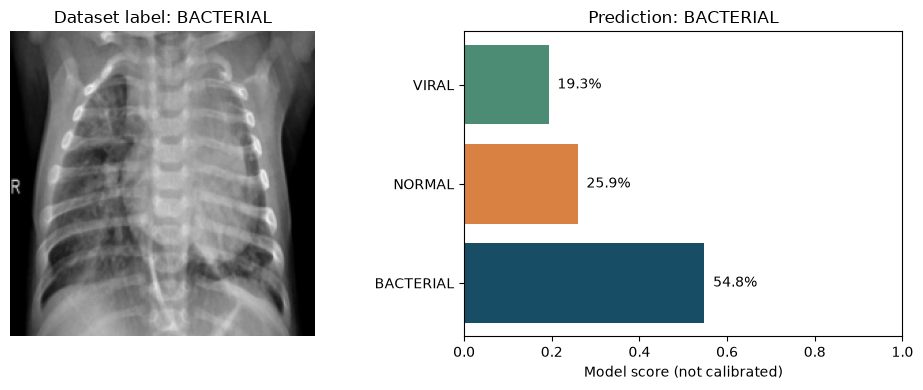

Dataset label: NORMAL Prediction: NORMAL


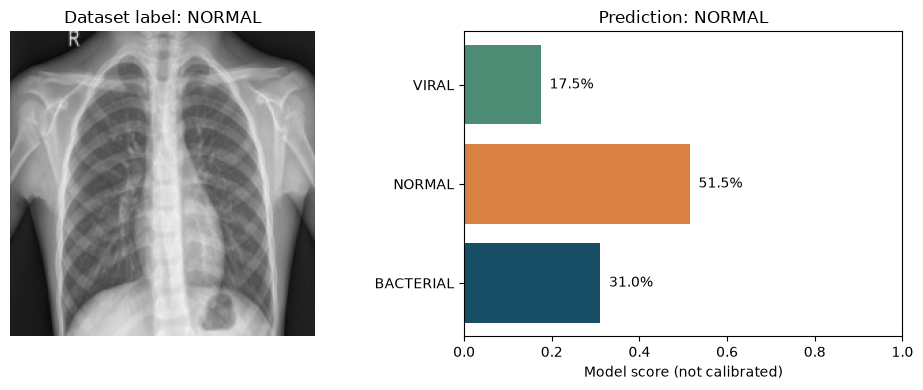

Dataset label: VIRAL Prediction: BACTERIAL


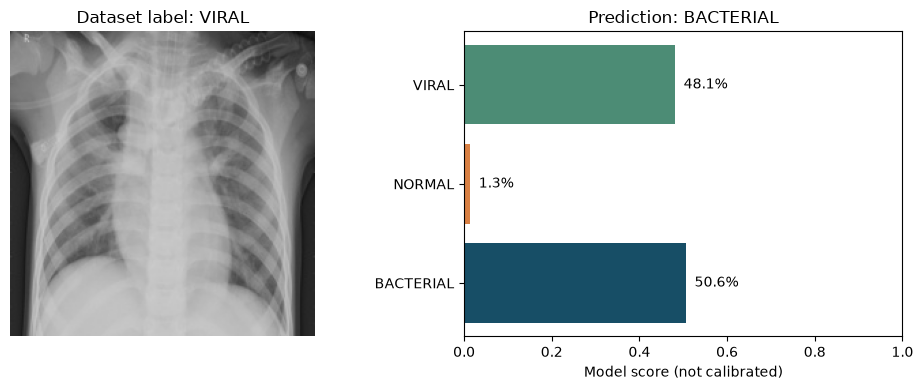

In [12]:
# The class order is printed in H02; choose one saved example per class.
for label, name in enumerate(class_names):
    image_path, known_label = next(sample for sample in test_data.samples if sample[1] == label)
    result = predict(image_path)
    print("Dataset label:", name, "Prediction:", result["label"])
    show_prediction(image_path, result, true_label=name,
                    output=f"homework_outputs/prediction_{name}.png")


<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H12 · Grad-CAM للصورة الأخيرة</h2><p>نفس Helper الخاصة بـMobileNetV2 تعمل مع الفئات الثلاث. نفحص مساهمة مناطق الصورة في Score الفئة المفسرة. لا نستنتج نوع العدوى أو مكان المرض من اللون الأحمر وحده.</p></div><div style="clear:both"></div></div>

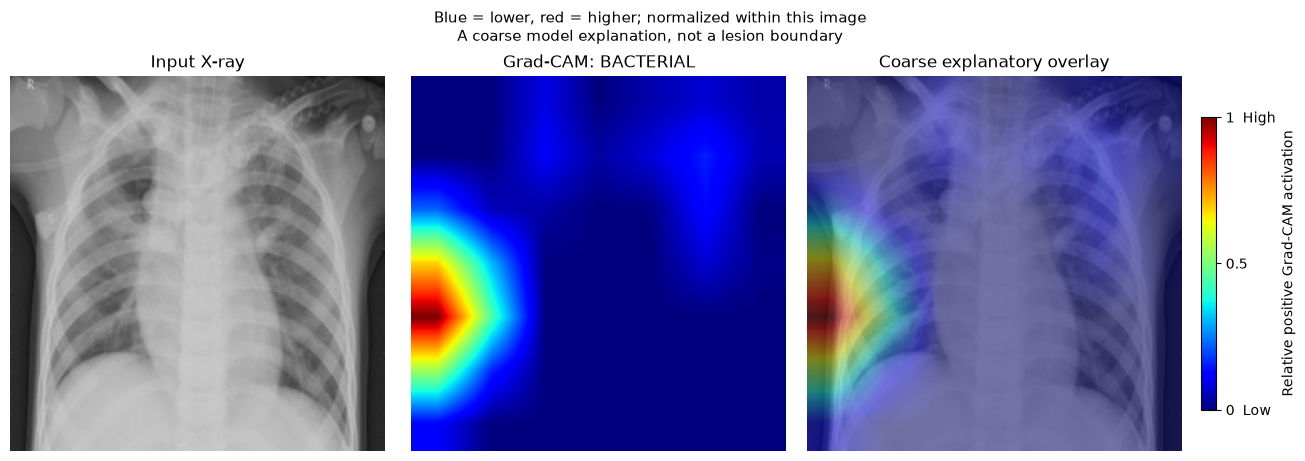

Explained class: BACTERIAL


In [13]:
# نفس الصورة ونفس النموذج؛ نحسب التفسير بدون تحديث Weights.
cam_info = show_gradcam(deployed_model, image_path, prediction_transform,
                        saved["class_names"], device, output="homework_outputs/gradcam.png")
print("Explained class:", cam_info["target_class"])

<div style="display:flow-root;width:100%"><div dir="rtl" lang="ar" style="float:right;width:100%;text-align:right;font-family:Cairo,Tahoma,sans-serif;line-height:1.9"><h2>H13 · المناقشة والتسليم</h2><p>أجب في الخلية التالية بالأرقام من تجربتك. سلّم Notebook مع <code dir="ltr">Pneumonia_Homework_Submission.zip</code>. لا تحتاج إرسال الصور الأصلية أو الأوزان.</p><p>التقييم من 10: صحة الفئات والمسار نقطتان، Classifier وLoss نقطتان، تشغيل التدريب والتقييم ثلاث نقاط، مناقشة الأخطاء بالأرقام نقطتان، واكتمال التسليم نقطة. لا توجد Accuracy إلزامية.</p></div><div style="clear:both"></div></div>

In [14]:
import csv
import zipfile

answers = {
    "student_name": "MOHAMMED ALANSI",
    "class_mapping_and_logits_shape": "الفئات مرتبة أبجدياً: BACTERIAL: 0، NORMAL: 1، VIRAL: 2. حجم الـ Logits لكل دفعة هو [N, 3] ولكل صورة [1, 3]، حيث يمثل كل عمود درجة غير معايرة لفئة من الفئات الثلاث.",
    "why_cross_entropy_still_works": "دالة CrossEntropyLoss تجمع بين LogSoftmax و NLLLoss وتستقبل Logits خام بأبعاد [N, C] وتسميات صحيحة [N]. وهي مصممة رياضياً للتصنيف متعدد الفئات C=3 تماماً كما في التصنيف الثنائي C=2 دون الحاجة لتطبيق Softmax يدوي مسبق.",
    "most_confused_classes_and_evidence": f"أكثر تداخل وخلط يحدث بين BACTERIAL و VIRAL؛ في مصفوفة الارتباك تم الخلط بينهما بسبب تقارب المظهر الشعاعي للالتهاب الرئوي، بينما يتميز NORMAL بدرجة دقة أعلى.",
    "limitation_and_next_validation_experiment": "القيود: استخراج الفئات مبني على الوسوم النصية بأسماء الملفات وليس تشخيصاً مخبرياً دقيقاً. التجربة القادمة على مجموعة التحقق: تطبيق Data Augmentation (تدوير خفيف، ضبط تباين) وضبط دقيق تدريجي (Fine-tuning) لآخر كتلتي ميزات مع مجدول معدل التعلم.",
}
assert all(v.strip() and not v.startswith("YOUR") for v in answers.values()), "Complete the homework discussion."
out = Path("homework_outputs")
out.mkdir(exist_ok=True)
with (out / "class_metrics.csv").open("w", encoding="utf-8", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["class", "recall", "test_images"])
    writer.writerows((name, float(per_class_recall[i]), int(cm[i].sum())) for i, name in enumerate(class_names))
(out / "discussion.txt").write_text(
    "\n\n".join(f"{k}: {v}" for k, v in answers.items())
    + f"\n\nAccuracy: {test_accuracy:.4f}\nMacro recall: {macro_recall:.4f}", encoding="utf-8"
)
with zipfile.ZipFile("Pneumonia_Homework_Submission.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(out.iterdir()):
        if path.suffix in {".png", ".csv", ".txt"}:
            archive.write(path, path.name)
print("Submit your homework notebook and Pneumonia_Homework_Submission.zip.")


Submit your homework notebook and Pneumonia_Homework_Submission.zip.